<a href="https://colab.research.google.com/github/Nicolas-Bernal/pronostico-precipitacion-ibague-arima/blob/main/Pronostico_Precipitacion_Ibague_IDEAM_ARIMA_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# $1$ EXTRACCION DE DATOS Y LIMPIEZA

In [ ]:
# Librerias


library(ggplot2)
library(readxl)
library(dplyr)
library(forecast)
library(tseries)

## Datos y algunas variables

In [ ]:
# Datos extraccion de datos y un poco de exploracion

datos1 = read_excel("Datos Precipitacion  ibague 2000-2026.xlsx",skip = 7)
datos = as.data.frame(datos1)
tail(datos)

# Generacion De Algunas Variables

precipitacion = as.numeric(datos[,3])

fecha = datos[,1]

mediap = mean(precipitacion)

sdp = sd(precipitacion)

serie_p = ts(precipitacion, start = c(2000,11),frequency = 12)

New names:
• `` -> `...2`
• `` -> `...4`


,Fecha,...2,Valor:,...4,Nivel de Aprobación
,<chr>,<lgl>,<chr>,<lgl>,<chr>
297,2026-05-01 00:00,NA,53.8,NA,Preliminar
298,2026-06-01 00:00,NA,81.9,NA,Preliminar
299,2026-07-01 00:00,NA,13.5,NA,Preliminar
300,2026-08-01 00:00,NA,43.2,NA,Preliminar
301,2026-09-01 00:00,NA,87,NA,Preliminar
302,2026-10-01 00:00,NA,87.8,NA,Preliminar


## Graficos y Pruebas de Normalidad

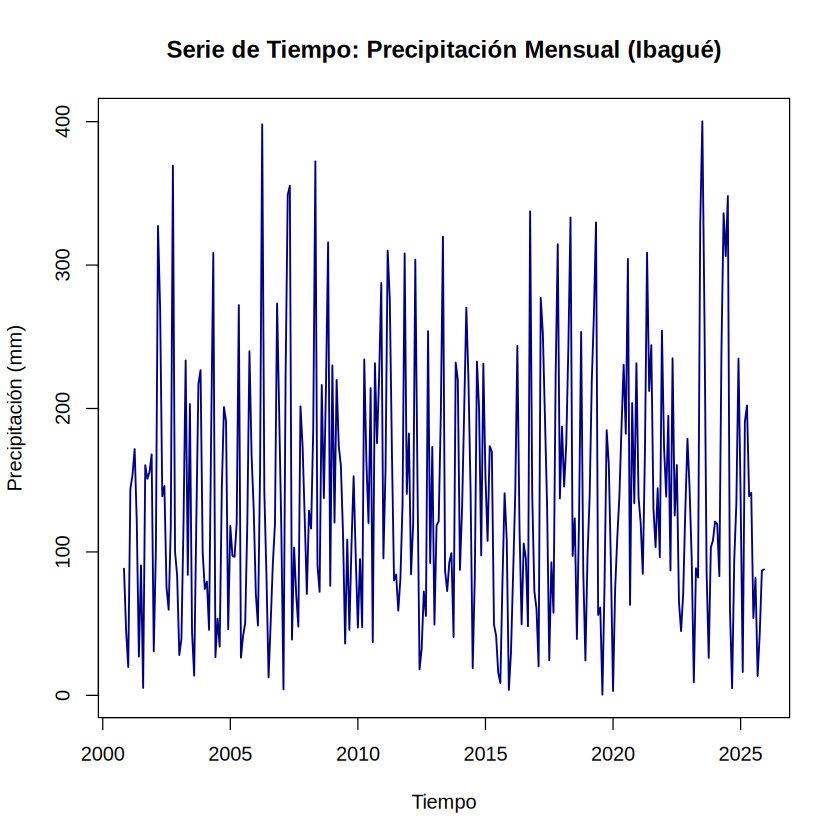

In [ ]:
# Grafico Exploratorio

plot(serie_p, main = "Serie de Tiempo: Precipitación Mensual (Ibagué)",
     ylab = "Precipitación (mm)", xlab = "Tiempo", col = "darkblue", lwd = 1.5)


	Shapiro-Wilk normality test

data:  serie_p
W = 0.95012, p-value = 1.323e-08



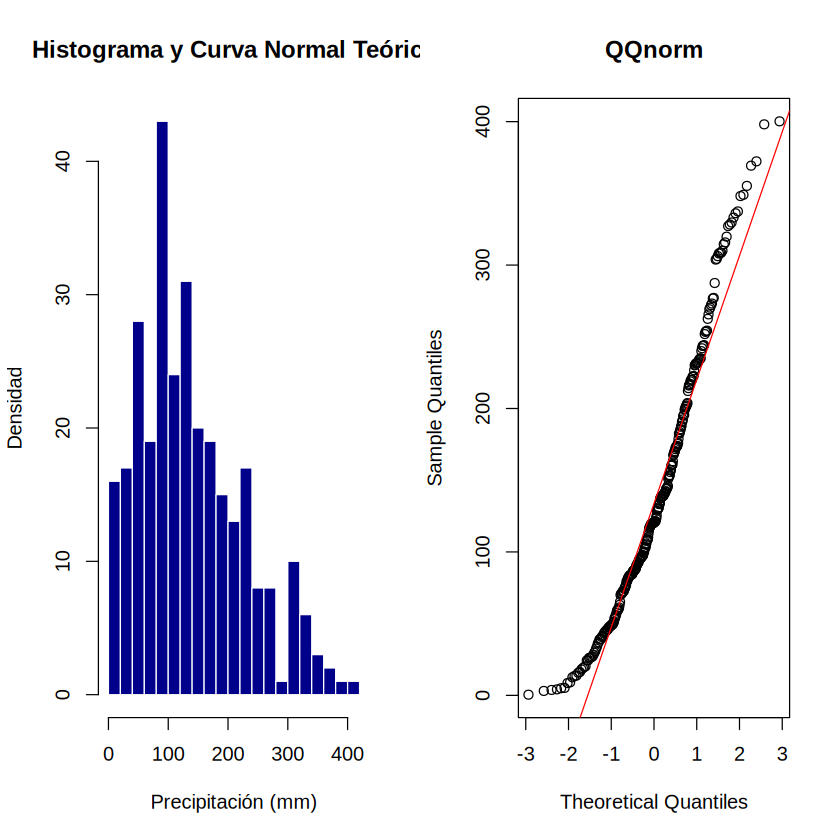

In [ ]:
# Prueba De Normalidad

par(mfrow = c(1,2))
hist(serie_p,
     probability = FALSE,col = "darkblue",border = "white",main = "Histograma y Curva Normal Teórica",xlab = "Precipitación (mm)",ylab = "Densidad",breaks = 20,)
qqnorm(serie_p, main = "QQnorm")
qqline(serie_p, col = "red")

shapiro_resultado = shapiro.test(serie_p)
print(shapiro_resultado)

### Observacion de la Normalidad

En los graficos nose observa algun rastro de normaldad ni en la distribucion ni en el qqnorm luego de esto vamos a aplicar una prueba analitica de shapiro para mostrar la no normalidad y conseguimos un
p-value = 1.323e-0 lo que rechaza la hipotesis nula

* Hipótesis Nula ($H_0$): Los datos siguen una distribución normal. (Si el p-valor es mayor a 0.05, aceptamos esta hipótesis).

* Hipótesis Alternativa ($H_1$): Los datos no siguen una distribución normal. (Si el p-valor es menor a 0.05, rechazamos la normalidad).

## Correlacion y Correlacion Parcial

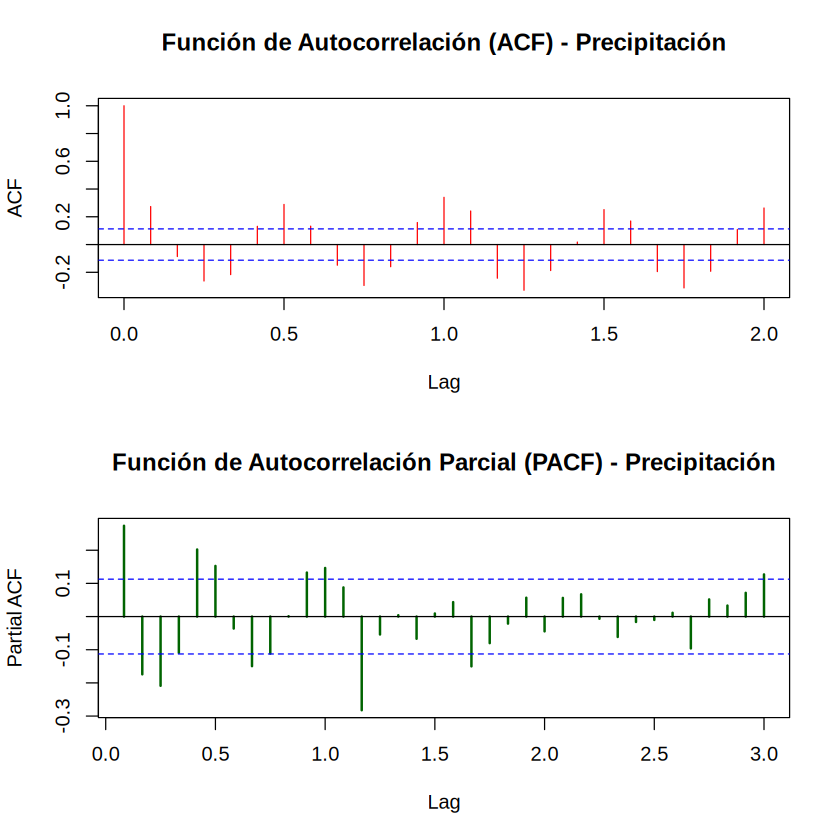

In [ ]:
par(mfrow = c(2,1))
acf(serie_p,main = "Función de Autocorrelación (ACF) - Precipitación",col = "red")
pacf(serie_p, main = "Función de Autocorrelación Parcial (PACF) - Precipitación", lag.max = 36, col = "darkgreen", lwd = 2)

### Observaciones de la Estacionalidad

* En el gráfico ACF (el rojo de arriba), las autocorrelaciones caen rápidamente y se mantienen relativamente bajas o oscilan cerca de cero después de los primeros rezagos (no se ve ese decaimiento lento en forma de escalera típico de las series con tendencia pura). Esto es una buena señal de que la serie es estacionaria (o moderadamente estacionaria)

* Se aprecian pequeños picos recurrentes o patrones en ciertos retardos (lags), lo que tiene todo el sentido del mundo tratándose de precipitación, ya que la lluvia suele tener un fuerte componente estacional (épocas de invierno/verano recurrentes cada año).

# $2$ TRANSFORMACION DE DATOS

buscamos transformar los datos con box-cox aun sabiendo que no nos garantiza totalmente normalidad en la transformacion pero si una media y sd mas estable para trabajar sobre esos datos

### Normalidad

Medias de Datos Transformados :  8.655157
Sd de Datos Transformados :  2.355724


	Shapiro-Wilk normality test

data:  as.numeric(serie_boxcox)
W = 0.96686, p-value = 2.077e-06


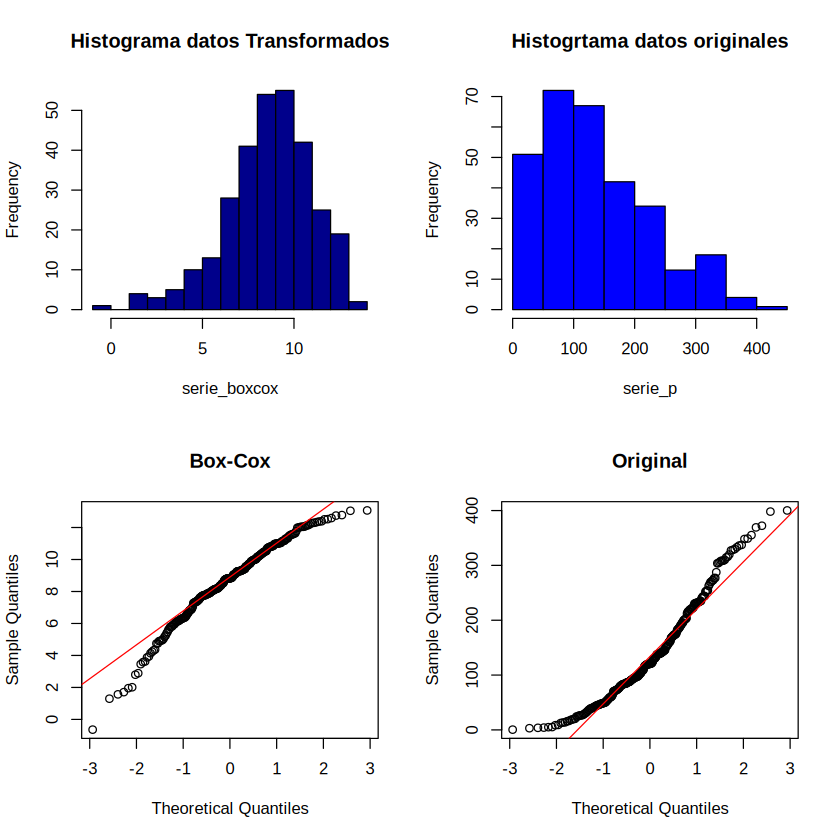

In [ ]:
# Estimacion del parametro lambda

lambda = BoxCox.lambda(serie_p)
serie_boxcox = BoxCox(serie_p,lambda = lambda)

# Graficos

par(mfrow = c(2,2))
hist(serie_boxcox,col = "darkblue",main = "Histograma datos Transformados",breaks = "FD",)
hist(serie_p,col = "blue",main = "Histogrtama datos originales")
qqnorm(serie_boxcox, main = "Box-Cox")
qqline(serie_boxcox, col = "red")
qqnorm(serie_p, main = "Original")
qqline(serie_p, col = "red")

mediat = mean(serie_boxcox)
sdt = sd(serie_boxcox)
cat("Medias de Datos Transformados : ",mediat)
cat("\nSd de Datos Transformados : ",sdt)

shapiro.test(as.numeric(serie_boxcox))

### Estacionalidad o no estacionalidad

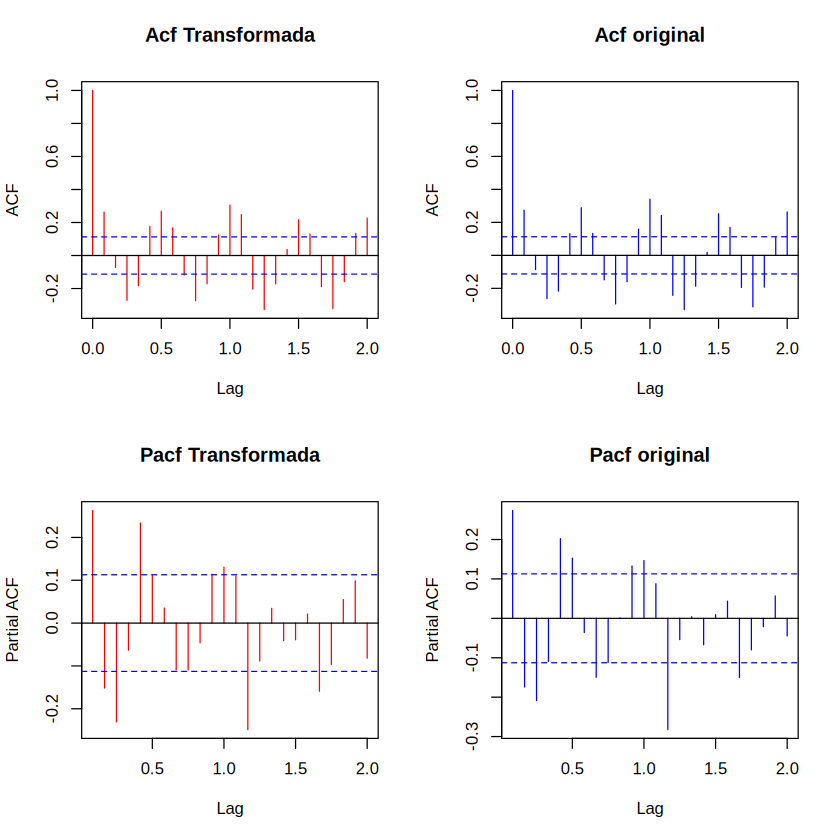

In [ ]:
par(mfrow = c(2,2))
acf(serie_boxcox,col = "red",main = "Acf Transformada")
acf(serie_p,col = "blue",main = "Acf original")
pacf(serie_boxcox,col = "red",main = "Pacf Transformada")
pacf(serie_p,col = "blue",main = "Pacf original")

* Se observa una gran correlacion con estacionalidad marcada en los datos transformados lo que me lleva a hacer una prueba analitica para salir de dudas

#### Prueba de Estacionalidad sobre los datos transformados

* Prueba ADF: La hipótesis nula ($H_0$) es que la serie no es estacionaria (tiene una raíz unitaria). Si el p-valor < 0.05, rechazamos $H_0$ y concluimos que sí es estacionaria.

* Prueba KPSS: La hipótesis nula ($H_0$) es que la serie es estacionaria. Si el p-valor < 0.05, rechazamos $H_0$ y concluimos que no es estacionaria.

In [ ]:
# ADF

estacionaridad1 = adf.test(serie_boxcox)
cat("ADF : ")
estacionaridad1

# KPSS

estacionaridad2 = kpss.test(serie_boxcox)
cat("KPSS : ")
estacionaridad2

Warning message in adf.test(serie_boxcox):
“p-value smaller than printed p-value”


ADF : 


	Augmented Dickey-Fuller Test

data:  serie_boxcox
Dickey-Fuller = -5.1216, Lag order = 6, p-value = 0.01
alternative hypothesis: stationary


Warning message in kpss.test(serie_boxcox):
“p-value greater than printed p-value”


KPSS : 


	KPSS Test for Level Stationarity

data:  serie_boxcox
KPSS Level = 0.11373, Truncation lag parameter = 5, p-value = 0.1


#### Conclusion Estacionalidad

Tras aplicar la transformación Box-Cox, se evaluó la estacionariedad de la serie mediante las pruebas ADF y KPSS. La prueba ADF arrojó un p-valor de 0.01 ($p < 0.05$), rechazando la presencia de raíz unitaria, mientras que la prueba KPSS arrojó un p-valor de 0.10 ($p > 0.05$), confirmando estacionariedad en nivel. Al ser concordantes ambos resultados, se concluye que la serie serie_boxcox es estacionaria y no requiere diferenciación ordinaria ($d = 0$), permitiendo continuar directamente con la identificación de los órdenes $p$ y $q$ para el modelo ARIMA."

# $3$ MODELADO Y SELECCIÓN ARIMA

## El mejor modelo

De las conclusiones de la seccion pasada tenemos que nuestros datos ya transformados son totalmente estacionarios por lo que no tenemos que hacer otra transformacion para generar estacionalidad nuestro grado de diferencia es d = 0 por lo que podemos aplicar un modelo SARIMA(p,0,q) y tambien ARIMA(p,d,q) con d = 0 luego ya sabiendo eso vamos a generar 16 modelos aplicando diferentes conbinaciones en sus periodos para observar cual es la mejor.

In [12]:
arima1 = Arima(serie_boxcox,order = c(1,0,1), seasonal = list(order = c(0,0,0),period = 12))
arima2 = Arima(serie_boxcox,order = c(1,0,1), seasonal = list(order = c(1,0,1),period = 12))
arima3 = Arima(serie_boxcox,order = c(1,0,1), seasonal = list(order = c(1,0,0),period = 12))
arima4 = Arima(serie_boxcox,order = c(1,0,1), seasonal = list(order = c(0,0,1),period = 12))

arima5 = Arima(serie_boxcox,order = c(0,0,1), seasonal = list(order = c(0,0,0),period = 12))
arima6 = Arima(serie_boxcox,order = c(0,0,1), seasonal = list(order = c(1,0,1),period = 12))
arima7 = Arima(serie_boxcox,order = c(0,0,1), seasonal = list(order = c(1,0,0),period = 12))
arima8 = Arima(serie_boxcox,order = c(0,0,1), seasonal = list(order = c(0,0,1),period = 12))

arima9  = Arima(serie_boxcox,order = c(1,0,0), seasonal = list(order = c(0,0,0),period = 12))
arima10 = Arima(serie_boxcox,order = c(1,0,0), seasonal = list(order = c(1,0,1),period = 12))
arima11 = Arima(serie_boxcox,order = c(1,0,0), seasonal = list(order = c(1,0,0),period = 12))
arima12 = Arima(serie_boxcox,order = c(1,0,0), seasonal = list(order = c(0,0,1),period = 12))

arima13 = Arima(serie_boxcox,order = c(2,0,2), seasonal = list(order = c(0,0,0),period = 12))
arima14 = Arima(serie_boxcox,order = c(2,0,2), seasonal = list(order = c(1,0,1),period = 12))
arima15 = Arima(serie_boxcox,order = c(2,0,2), seasonal = list(order = c(1,0,0),period = 12))
arima16 = Arima(serie_boxcox,order = c(2,0,2), seasonal = list(order = c(0,0,1),period = 12))

modelos = list(arima1,arima2,arima3,arima4,
    arima5,arima6,arima7,arima8,
    arima9,arima10,arima11,arima12,
    arima13,arima14,arima15,arima16)

In [13]:
v_aic = sapply(modelos, AIC)
v_bic = sapply(modelos, BIC)

tabla_modelos = data.frame(
  Modelo = paste0("arima", 1:16),
  AIC = v_aic,
  BIC = v_bic
)

tabla_modelos

Modelo,AIC,BIC
<chr>,<dbl>,<dbl>
arima1,1357.305,1372.147
arima2,1317.254,1339.516
arima3,1340.665,1359.217
arima4,1344.618,1363.170
arima5,1355.474,1366.606
arima6,1315.745,1334.297
arima7,1339.368,1354.210
arima8,1343.143,1357.984
arima9,1357.990,1369.122


In [14]:
auto.arima(serie_boxcox)

Series: serie_boxcox 
ARIMA(1,0,0)(1,0,0)[12] with non-zero mean 

Coefficients:
         ar1    sar1    mean
      0.1981  0.2768  8.6216
s.e.  0.0580  0.0585  0.2138

sigma^2 = 4.831:  log likelihood = -665.34
AIC=1338.68   AICc=1338.82   BIC=1353.52

### ARIMA13(2,0,2)

bajo esta generacion de modelos vamos a aplicar un AIC y un BIC que lo que hace es premiar los modelos dependiendo algunas condiciones bajo este analisis de cual es el modelo que arroja el menor numero lo que se traduce al mejor modelo es el

arima13 que es el que tiene un orden (2,0,2) y estacionalidad (0,0,0)

Cuando usamos la funcion auto.arima nos arroja que el mejor modelo para nuestra serie dentro de nuestro codigo es arima11 por que elejimos arima13 y no arima11 por que el metodo de auto.arima evalua secuencialmente todos los p y q mas no las cobinaciones en las condiciones que hay por lo que ese auto.arima no llego ni a calcular las condiciones que nosotros si calculamos (2,0,2) ya que nostros trabajos todo el espacio de combinaciones de 16 modelos y auto.arima solo evaluo 11 modelos

# $4$ DIAGNÓSTICO DE RESIDUOS

## Pruebas de Normalidad en los residuos


	Shapiro-Wilk normality test

data:  error_modelo
W = 0.97388, p-value = 2.622e-05


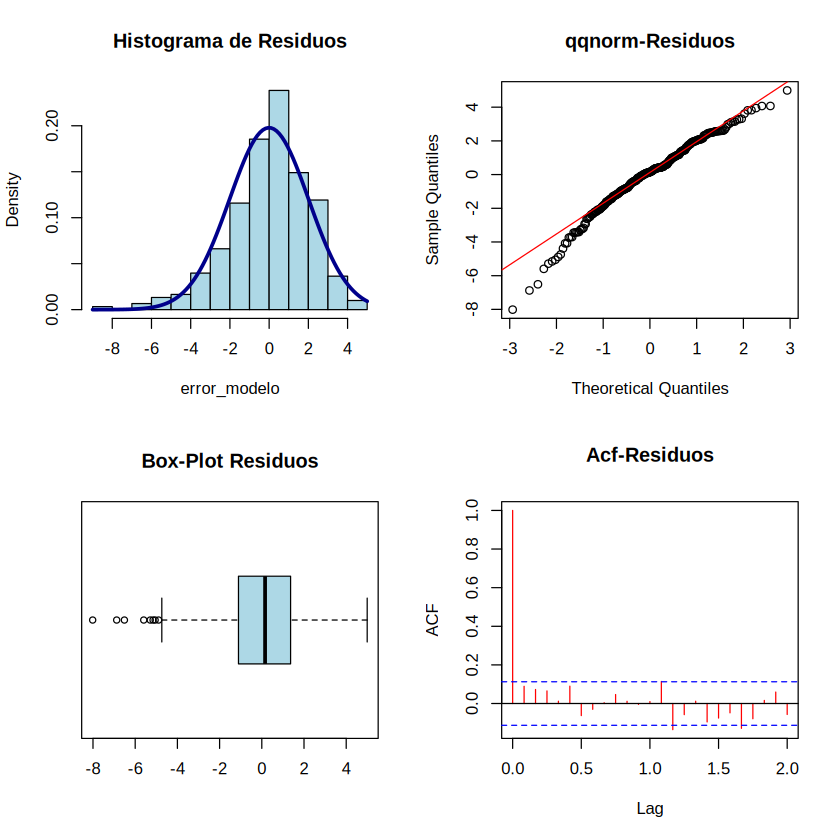

In [15]:
error_modelo = residuals(arima13)
error_media = mean(error_modelo)
error_sd = sd(error_modelo)

par(mfrow = c(2,2))
hist(error_modelo,freq = FALSE,breaks = "FD",main = "Histograma de Residuos",col = "lightblue")
curve(dnorm(x,mean = error_media,sd = error_sd),add = TRUE,col = "darkblue",lwd = 3)
qqnorm(error_modelo,main = "qqnorm-Residuos")
qqline(error_modelo,col = "red")
boxplot(error_modelo,horizontal = TRUE,col = "lightblue",main = "Box-Plot Residuos")
acf(error_modelo,col = "red",main = "Acf-Residuos")

shapiro.test(error_modelo)

* Se observa una simetria entre los residuos y la curva teorica ademas de que si se pudo generar una curva teorica con su media y sd lo que mas aun refuta la normaldad luego encontramos algunas colas pesadas en el qqnorm pero eso es debido al efecto del estudio en precipitacion un boxplot con una media central marcada y un acf que tiene una minima demasiado peque;a correlacion que nos puede hacer dudar de su estacionalidad luego una prueba analitica para refutar la normalidad sobre estos residuos que arroja un p-value = 2.622e-05, este rechazo de normalidad se profundiza mas en las notas pero vamos a concluir que si es normal los residuos

* Hipótesis Nula ($H_0$): Los datos siguen una distribución normal. (Si el p-valor es mayor a 0.05, aceptamos esta hipótesis).

* Hipótesis Alternativa ($H_1$): Los datos no siguen una distribución normal. (Si el p-valor es menor a 0.05, rechazamos la normalidad).


	Box-Ljung test

data:  error_modelo
X-squared = 32.085, df = 20, p-value = 0.0424


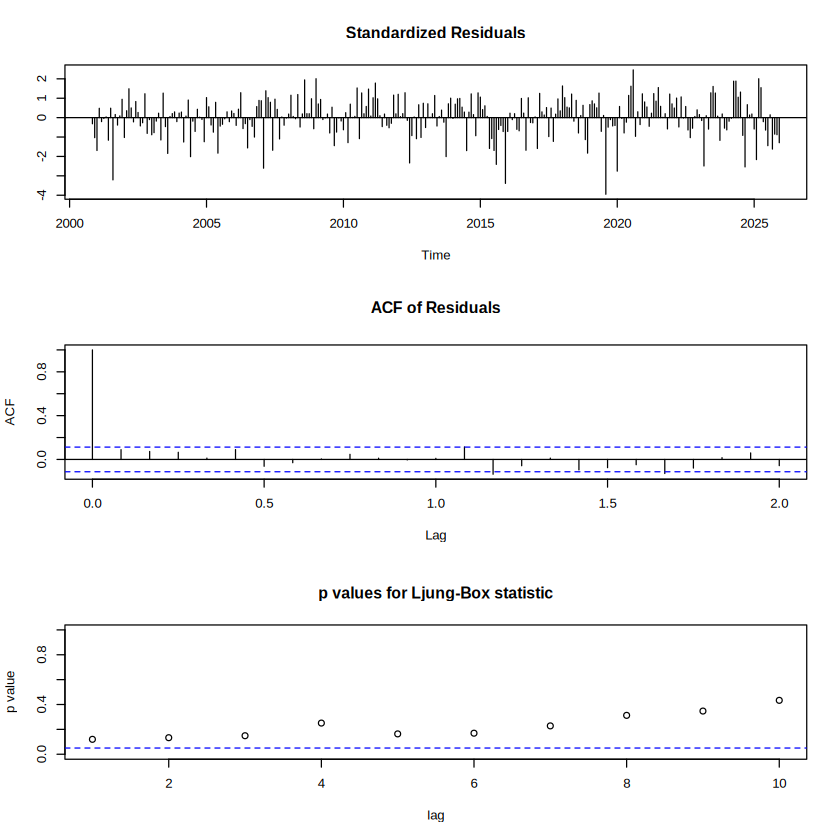

In [16]:
tsdiag(arima13)
Box.test(error_modelo, lag = 20, type = "Ljung-Box")

# $5$ PRONOSTICO (2026 - 2027)

Una vez ya tenemos el modelo seleccionado y sabemos que sus residuos son normales lo mas adecuado es primero aplicar una transformacion inversa en los datos para entregar los pronosticos de una forma mas optima y con la naturaleza de la precipitacion

## Transformacion InversaBOX-COX

In [18]:
inv_boxcox = InvBoxCox(serie_boxcox, lambda = lambda)

arima13R = Arima(inv_boxcox,order = c(2,0,2), seasonal = list(order = c(0,0,0),period = 12))

pronosticoR = forecast(arima13R, h = 24)

## Grafica del Pronostico

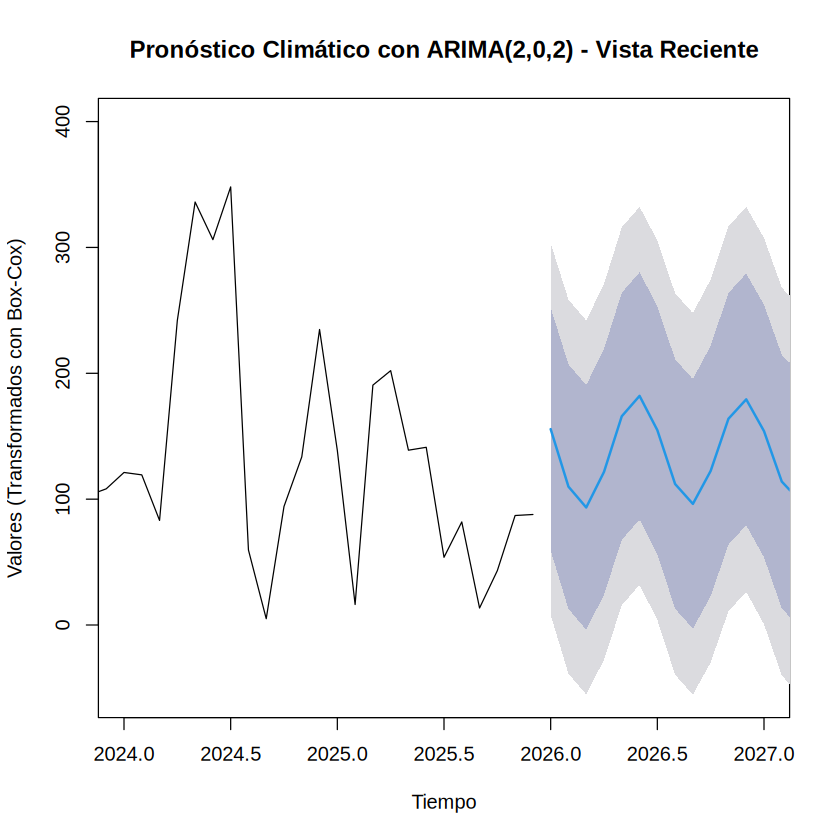

In [20]:
plot(pronosticoR,
     main = "Pronóstico Climático con ARIMA(2,0,2) - Vista Reciente",
     ylab = "Valores (Transformados con Box-Cox)",
     xlab = "Tiempo",
     xlim = c(2024, 2027))

### Algunas observaciones

* Patrón Estacional Estable: El modelo ARIMA(2,0,2) proyecta para los periodos 2026 y 2027 una estacionalidad cíclica muy marcada y constante, replicando de manera fiel el comportamiento oscilatorio observado en los años históricos anteriores (2024-2025)

* Comportamiento de la Tendencia Central: La línea de pronóstico puntual (en azul) mantiene una amplitud regular en sus picos y valles a lo largo de todo el horizonte de predicción a 24 meses, indicando que no se anticipan tendencias abruptas al alza o a la baja a largo plazo, sino un retorno al comportamiento periódico habitual.

# $6$ GENERACION TABLAS MES A MES (2026 / 2027)

## Tabla 2026

In [21]:
tabla_2026 = data.frame(
  Mes = c("Ene", "Feb", "Mar", "Abr", "May", "Jun",
          "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"),
  Point_Forecast = window(pronosticoR$mean, start = c(2026, 1), end = c(2026, 12)),
  Lo_80          = window(pronosticoR$lower[, 1], start = c(2026, 1), end = c(2026, 12)),
  Hi_80          = window(pronosticoR$upper[, 1], start = c(2026, 1), end = c(2026, 12)),
  Lo_95          = window(pronosticoR$lower[, 2], start = c(2026, 1), end = c(2026, 12)),
  Hi_95          = window(pronosticoR$upper[, 2], start = c(2026, 1), end = c(2026, 12))
)


print(tabla_2026)

   Mes Point_Forecast     Lo_80    Hi_80      Lo_95    Hi_95
1  Ene      155.62399 59.080778 252.1672   7.973887 303.2741
2  Feb      109.94449 12.789647 207.0993 -38.641023 258.5300
3  Mar       93.38873 -3.777094 190.5546 -55.213574 241.9910
4  Abr      121.66131 24.060993 219.2616 -27.605494 270.9281
5  May      165.87689 67.708461 264.0453  15.741233 316.0126
6  Jun      182.04512 83.865921 280.2243  31.892991 332.1973
7  Jul      154.82038 56.240929 253.3998   4.056120 305.5846
8  Ago      112.02240 12.914809 211.1300 -39.549580 263.5944
9  Sep       96.23424 -2.883909 195.3524 -55.353889 247.8224
10 Oct      122.44906 22.961912 221.9362 -29.703403 274.6015
11 Nov      163.87431 63.895812 263.8528  10.970391 316.7782
12 Dic      179.28979 79.300940 279.2786  26.370042 332.2095


## Tabla 2027

In [22]:
tabla_2027 = data.frame(
  Mes = c("Ene", "Feb", "Mar", "Abr", "May", "Jun",
          "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"),
  Point_Forecast = window(pronosticoR$mean, start = c(2027, 1), end = c(2027, 12)),
  Lo_80          = window(pronosticoR$lower[, 1], start = c(2027, 1), end = c(2027, 12)),
  Hi_80          = window(pronosticoR$upper[, 1], start = c(2027, 1), end = c(2027, 12)),
  Lo_95          = window(pronosticoR$lower[, 2], start = c(2027, 1), end = c(2027, 12)),
  Hi_95          = window(pronosticoR$upper[, 2], start = c(2027, 1), end = c(2027, 12))
)

print(tabla_2027)

   Mes Point_Forecast      Lo_80    Hi_80       Lo_95    Hi_95
1  Ene      154.04833 53.7190568 254.3776   0.6079487 307.4887
2  Feb      113.95233 13.1656191 214.7390 -40.1876438 268.0923
3  Mar       98.90222 -1.8946208 199.6991 -55.2532460 253.0577
4  Abr      123.20559 22.0944813 224.3167 -31.4305066 277.8417
5  May      162.01444 60.4772015 263.5517   6.7266319 317.3023
6  Jun      176.70643 75.1592792 278.2536  21.4034642 332.0094
7  Jul      153.30713 51.4696979 255.1446  -2.4397849 309.0541
8  Ago      115.74463 13.5099986 217.9793 -40.6097441 272.0990
9  Sep      101.40360 -0.8407125 203.6479 -54.9655826 257.7728
10 Oct      123.93163 21.4190454 226.4442 -32.8478396 280.7111
11 Nov      160.28732 57.4043314 263.1703   2.9413684 317.6333
12 Dic      174.28446 71.3920143 277.1769  16.9240430 331.6449


In [23]:
tabla_2026[1,2]
datos[293,3]

[1] 155.624

[1] "190.6"